# Reconstrucción v2
Nueva ejecución de la receta auditada; no se reutilizan salidas ni run_id de v1. Misma entrada congelada y folds. La selección de modelos incluirá seis candidatos y el criterio del negocio desde el diseño. 2014J es un benchmark previamente observado.

# 01 · EDA de desarrollo: decisiones antes de modelar

Wilmer Puerta · PSet 3 · Día 56

Se analizan **solo las matrículas de desarrollo congeladas**. La prueba 2014J permanece reservada. Las tablas y figuras son descriptivas: no se ajustan modelos ni imputadores ni se calcula rendimiento en hold-out. Las 37 columnas cargadas son las 35 originales OBT más `target_class` y `cv_fold`; el fold, las claves y los campos de auditoría no son predictores.

La preparación de modelos permanece centralizada en `src/pipeline.py`. Este notebook importa esa preparación y la carga verificada; el cálculo estadístico reproducible vive en `src/eda.py`.

In [1]:
from pathlib import Path
import sys, os, json, hashlib, subprocess
here = Path.cwd().resolve()
BASE = next((p for p in [here, *here.parents] if (p/'config/protocolo-v2.json').is_file()), None)
if BASE is None and (here/'pset_3/config/protocolo-v2.json').is_file(): BASE=here/'pset_3'
assert BASE is not None, 'Ejecutar desde pset_3 o notebooks; revisar README'
sys.path.insert(0, str(BASE))
os.environ['MPLCONFIGDIR'] = str(BASE / '.local/matplotlib')
from IPython.display import display, Markdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from src.datos import cargar_snapshot, pliegues_congelados
from src.pipeline import construir_pipeline
from src.eda import analizar, figuras, exportar, hallazgos
from src.common import read_bundle, sha256
from src.tracking import configurar
pd.set_option('display.max_rows', 45)
pd.set_option('display.max_columns', 16)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

## 1. Población y procedencia

Una fila por matrícula en día 56. Se preservan los alumnos con varias matrículas y se informa también la cantidad de personas. No se muestran filas individuales ni identificadores. La selección corresponde a la cohorte común elegible al día 56 y no se extrapola a quienes ya se retiraron antes de ese corte.

In [2]:
train, snapshot_id = cargar_snapshot()
assert train.attrs['partition'] == 'train'
cv = list(pliegues_congelados(train))
result = analizar(train)
s = result['summary']
t = result['tables']
display(pd.DataFrame([{'matriculas': s['rows'], 'alumnos_unicos': s['unique_students'],
                       'columnas_OBT': s['original_obt_columns'], 'columnas_cargadas': s['columns_loaded'],
                       'corte_dia': s['cutoff_day'], 'folds_congelados': len(cv)}]))
print('snapshot_id:', snapshot_id)
print('split_id:', s['split_id'])
print('Instante de extracción UTC:', s['snapshot_at_utc'])
display(pd.DataFrame([{'control': k, 'aprobado': v} for k,v in s['checks'].items()]))

,matriculas,alumnos_unicos,columnas_OBT,columnas_cargadas,corte_dia,folds_congelados
0,16331,15482,35,37,56,5


snapshot_id: 0a75615bd8ff6b166d366cf78c8303845852cbeb23387ac24a64fe4962f01027
split_id: 231cd638f375de2a8c70b4482fdf6a98dbe022371a409f1fc92bc97189cf7736
Instante de extracción UTC: 2026-11-16T19:38:45.158000-08:00


,control,aprobado
0,train_rows_match_frozen,True
1,no_missing_target,True
2,no_missing_ids,True
3,counter_reconciliation,True
4,recency_missing_exactly_no_recorded_activity,True
5,ratio_missing_exactly_zero_previous_window,True
6,current_active_days_between_0_and_14,True
7,recency_matches_last_day,True
8,no_negative_click_counters,True
9,no_target_leakage_into_original_features,True


## 2. Tipos, roles, faltantes y descriptivos

El perfil cubre **todas las columnas cargadas**. Los descriptivos numéricos se limitan a variables candidatas permitidas por el contrato: no se correlacionan IDs ni códigos ni números de fold. Se conservan los tipos originales y los faltantes. Las frecuencias categóricas no convierten sus categorías en números ordinales arbitrarios.

In [3]:
display(t['perfil_columnas'])
display(t['descriptivos_numericos'].round(3))
display(t['categorias'])

,columna,tipo,rol,faltantes,faltantes_pct,valores_distintos_observados
0,enrollment_key,string,identificador_no_predictor,0,0.0000,16331
1,cutoff_day,Int64,identificador_no_predictor,0,0.0000,1
2,id_student,Int64,identificador_no_predictor,0,0.0000,15482
3,edition_key,string,identificador_no_predictor,0,0.0000,15
4,code_module,string,identificador_no_predictor,0,0.0000,7
5,code_presentation,string,identificador_no_predictor,0,0.0000,3
6,gender,string,predictor_estatico,0,0.0000,2
7,region,string,predictor_estatico,0,0.0000,13
8,highest_education,string,predictor_estatico,0,0.0000,5
9,imd_band,string,predictor_estatico,577,3.5332,10


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max,asimetria
variable,,,,,,,,,,,,
num_of_prev_attempts,"16,331.0000",0.1680,0.4850,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,2.0000,6.0000,3.7060
studied_credits,"16,331.0000",76.8810,38.5860,30.0000,30.0000,60.0000,60.0000,90.0000,150.0000,210.0000,630.0000,1.7840
module_presentation_length,"16,331.0000",250.5340,13.1150,234.0000,234.0000,240.0000,241.0000,268.0000,268.0000,268.0000,268.0000,0.3550
registration_days_before_start,"16,331.0000",66.8240,48.2560,1.0000,8.0000,29.0000,53.0000,93.0000,158.0000,214.0000,310.0000,1.2580
clicks_through_cutoff,"16,331.0000",558.1880,676.8770,0.0000,0.0000,131.0000,343.0000,730.0000,"1,805.0000","3,194.1000","9,860.0000",3.2510
clicks_since_start,"16,331.0000",475.8600,579.4000,0.0000,0.0000,109.0000,295.0000,629.0000,"1,552.5000","2,686.4000","9,182.0000",3.3390
clicks_prestart,"16,331.0000",73.3020,134.5390,0.0000,0.0000,2.0000,26.0000,85.5000,302.0000,626.7000,"2,809.0000",5.0540
clicks_day_zero,"16,331.0000",9.0260,24.2110,0.0000,0.0000,0.0000,0.0000,5.0000,52.0000,116.0000,439.0000,5.2850
active_days_through_cutoff,"16,331.0000",24.1970,17.0370,0.0000,0.0000,10.0000,21.0000,36.0000,57.0000,68.0000,75.0000,0.6510


,variable,categoria,n,pct
0,gender,M,8489,51.9809
1,gender,F,7842,48.0191
2,region,East Anglian Region,1771,10.8444
3,region,Scotland,1616,9.8953
4,region,South Region,1607,9.8402
5,region,London Region,1574,9.6381
6,region,North Western Region,1391,8.5175
7,region,West Midlands Region,1288,7.8868
8,region,South West Region,1247,7.6358
9,region,East Midlands Region,1145,7.0112


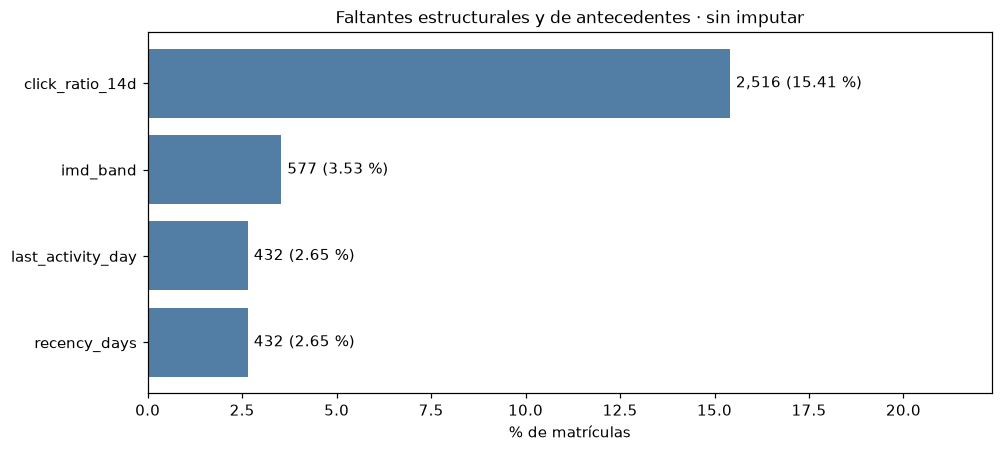

,variable,faltante,n,n_fail,tasa_fail
0,imd_band,False,15754,4823,0.3061
1,imd_band,True,577,95,0.1646
2,click_ratio_14d,False,13815,3417,0.2473
3,click_ratio_14d,True,2516,1501,0.5966
4,recency_days,False,15899,4591,0.2888
5,recency_days,True,432,327,0.7569


In [4]:
plots = figuras(train, result)
display(plots['02_faltantes'])
plt.close(plots['02_faltantes'])
display(t['faltantes_target'].round(4))

`recency_days` y `last_activity_day` faltan en las mismas matrículas sin registros. El último es auditoría; no se introducen ambos como predictores equivalentes. La razón actual/anterior es indefinida con denominador cero. IMD conserva su ausencia. No se imputan estas columnas durante EDA: la política se ajustará dentro de cada fold.

Una recencia mayor que 56 puede corresponder a la última interacción **antes del inicio**; no se convierte automáticamente en error. Cero clics registrados tampoco demuestra cero actividad académica real.

## 3. Target y desbalance

El target multiclase distingue `Approved` (Pass + Distinction), `Fail` y `Withdrawn`. La métrica principal futura se centra en P(Fail). No se transforma el target multiclase en una escala ordinal.

Las referencias de prevalencia y clase mayoritaria se calculan de forma descriptiva: **no son todavía corridas de baseline entrenadas**. El desbalance motiva métricas por clase y AP para Fail; no justifica por sí solo sobremuestreo ni SMOTE global.

,clase,n,pct
0,Approved,9219,56.4510
1,Fail,4918,30.1150
2,Withdrawn,2194,13.4350


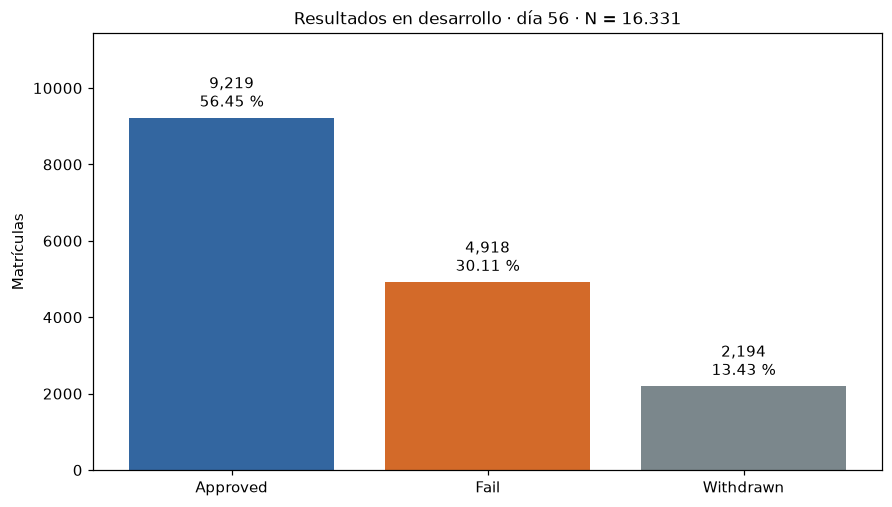

Razón clase mayoritaria/minoritaria: 4.202
Referencia accuracy de clase mayoritaria: 56.45 %
Prevalencia Fail (referencia para interpretar AP): 30.11 %


,cv_fold,n,n_fail,tasa_fail,Approved,Fail,Withdrawn
0,0,3276,1010,0.3083,1854,1010,412
1,1,3282,935,0.2849,1898,935,449
2,2,3265,963,0.2949,1825,963,477
3,3,3277,1032,0.3149,1817,1032,428
4,4,3231,978,0.3027,1825,978,428


In [5]:
display(t['target'].round(3))
display(plots['01_target']); plt.close(plots['01_target'])
print(f"Razón clase mayoritaria/minoritaria: {s['majority_minority_ratio']:.3f}")
print(f"Referencia accuracy de clase mayoritaria: {100*s['majority_class_accuracy_reference']:.2f} %")
print(f"Prevalencia Fail (referencia para interpretar AP): {100*s['fail_prevalence']:.2f} %")
display(t['balance_folds'].round(4))

## 4. Distribuciones y valores atípicos

IQR: marcar observaciones estrictamente fuera de [Q1−1,5×IQR, Q3+1,5×IQR]. Z-score: |(x−media)/σ| **≥3**, con σ poblacional (`ddof=0`) y solo valores observados. Con varianza cero, Z no está definido. Se informa también IQR cero: en variables discretas concentradas en cero puede marcar todos los valores positivos legítimos.

La tabla usa los cuartiles de todo desarrollo; los boxplots recalculan cuartiles dentro de cada clase, por lo que sus puntos extremos no son los conteos globales de la tabla. Los histogramas usan los mismos bordes de bins para las tres clases en cada variable.

Estas reglas describen extremos; no prueban error de datos ni normalidad. No se elimina ninguna matrícula. Las transformaciones de los histogramas son únicamente visuales; los boxplots mantienen los valores originales y usan escala symlog cuando facilita ver cajas y colas sin ocultar extremos.

,variable,n_observado,q1,q3,iqr,limite_inferior,limite_superior,iqr_cero,n_iqr,pct_iqr,media,std_poblacional,n_z_abs_ge_3,pct_z_abs_ge_3,z_definido
0,num_of_prev_attempts,16331,0.0000,0.0000,0.0000,0.0000,0.0000,True,2147,13.1470,0.1680,0.4850,463,2.8350,True
1,studied_credits,16331,60.0000,90.0000,30.0000,15.0000,135.0000,False,925,5.6640,76.8810,38.5850,197,1.2060,True
2,module_presentation_length,16331,240.0000,268.0000,28.0000,198.0000,310.0000,False,0,0.0000,250.5340,13.1140,0,0.0000,True
3,registration_days_before_start,16331,29.0000,93.0000,64.0000,-67.0000,189.0000,False,392,2.4000,66.8240,48.2550,175,1.0720,True
4,clicks_through_cutoff,16331,131.0000,730.0000,599.0000,-767.5000,"1,628.5000",False,1066,6.5270,558.1880,676.8570,303,1.8550,True
5,clicks_since_start,16331,109.0000,629.0000,520.0000,-671.0000,"1,409.0000",False,1032,6.3190,475.8600,579.3820,288,1.7640,True
6,clicks_prestart,16331,2.0000,85.5000,83.5000,-123.2500,210.7500,False,1484,9.0870,73.3020,134.5350,326,1.9960,True
7,clicks_day_zero,16331,0.0000,5.0000,5.0000,-7.5000,12.5000,False,3024,18.5170,9.0260,24.2100,368,2.2530,True
8,active_days_through_cutoff,16331,10.0000,36.0000,26.0000,-29.0000,75.0000,False,0,0.0000,24.1970,17.0360,0,0.0000,True
9,resources_through_cutoff,16331,17.0000,54.0000,37.0000,-38.5000,109.5000,False,359,2.1980,37.8480,29.1540,149,0.9120,True


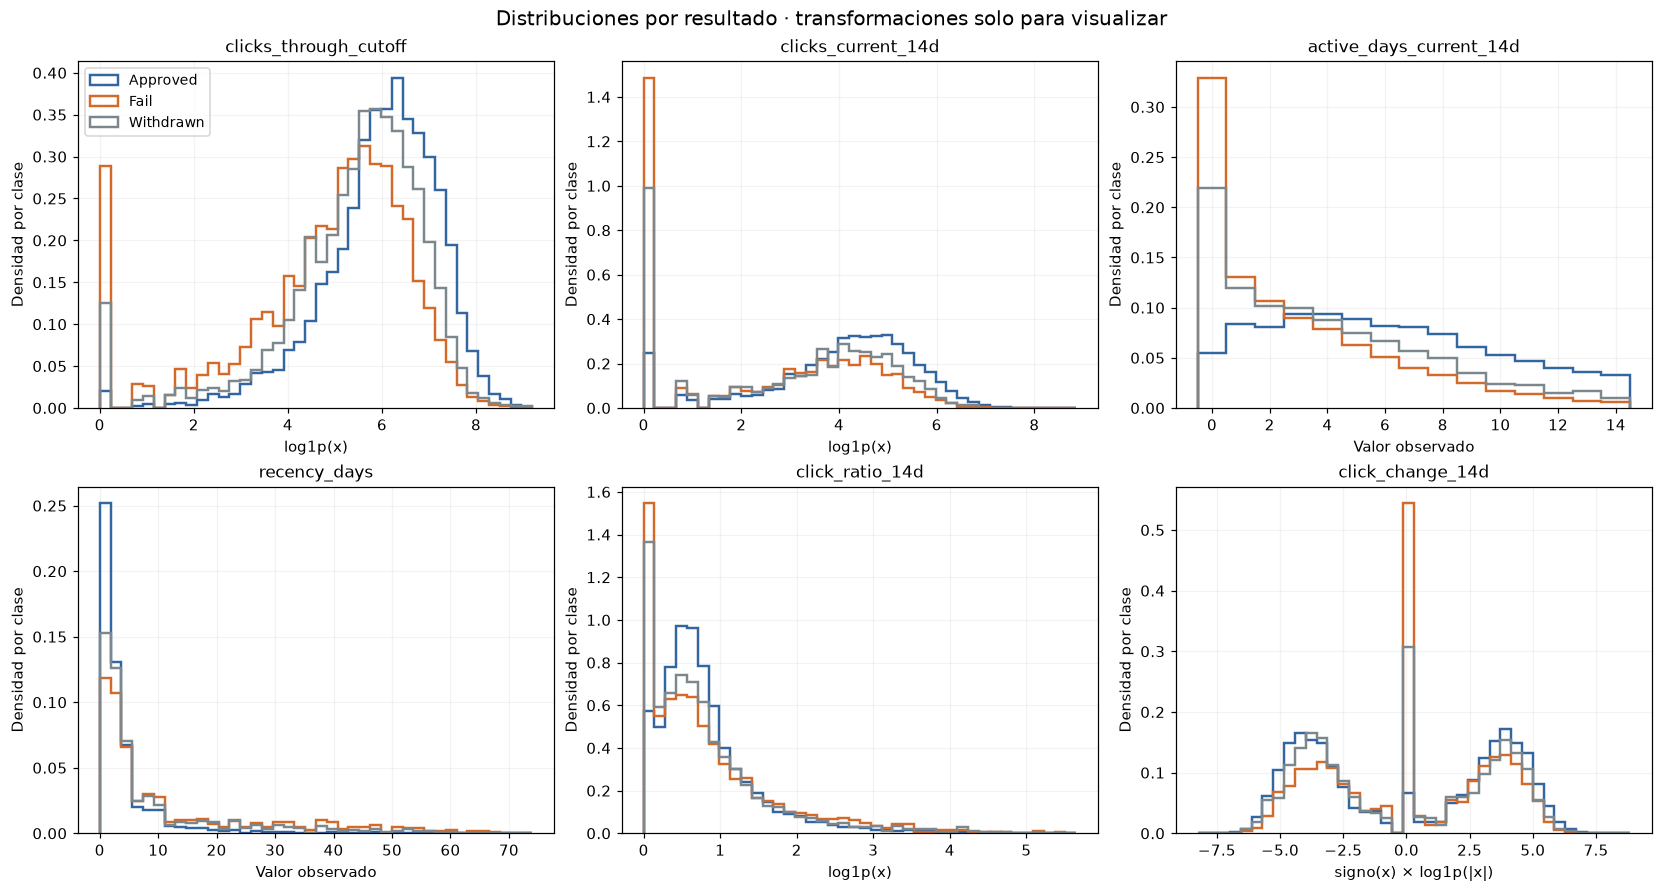

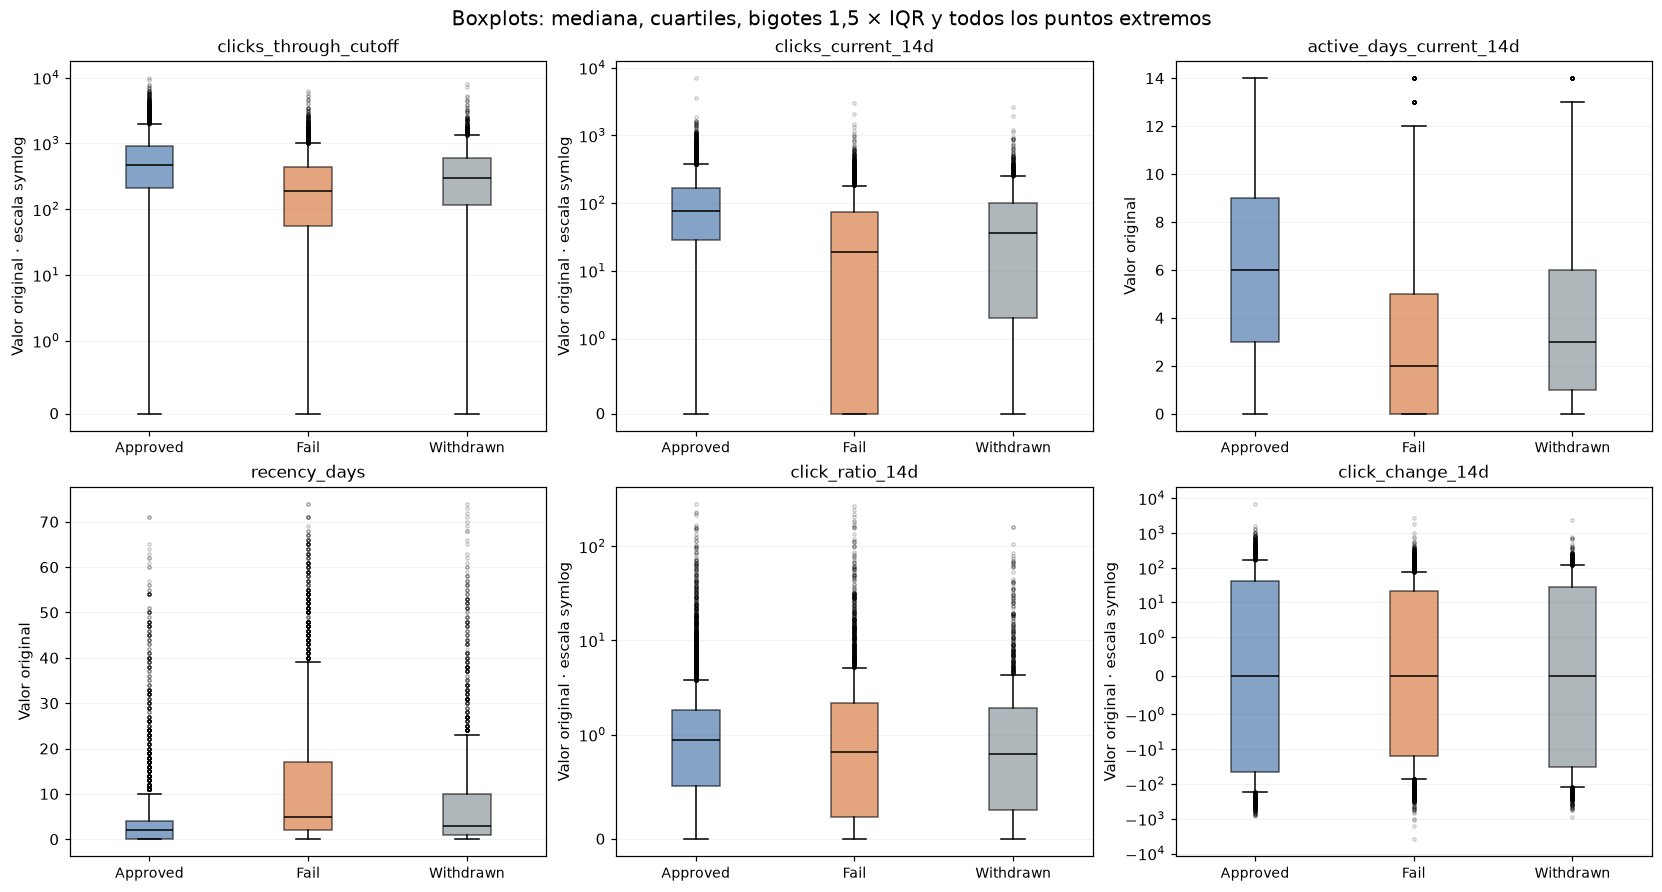

Filas eliminadas por outliers: 0


In [6]:
display(t['outliers'].round(3))
display(plots['03_distribuciones']); plt.close(plots['03_distribuciones'])
display(plots['04_boxplots_iqr']); plt.close(plots['04_boxplots_iqr'])
print('Filas eliminadas por outliers:', s['outlier_rows_removed'])

## 5. Relación entre características y Fail

Se usa **Spearman** porque varios conteos y razones son asimétricos, contienen extremos y no sugieren una relación lineal. Se correlacionan los rangos con `Fail`=1 frente al resto=0; los empates se resuelven por rangos medios. Cada coeficiente usa observados por pareja y se informa su N. Una variable con varianza cero no recibe un coeficiente artificial.

La matriz completa se exporta. La figura muestra diez asociaciones marginales de mayor magnitud para legibilidad: **esa visualización no selecciona automáticamente features**. No se calculan p-valores ni se afirma causalidad; varias matrículas pertenecen a un mismo alumno y la composición por módulo puede confundir estas relaciones. Las categóricas se examinan por frecuencias y tasas, sin codificación ordinal arbitraria.

,variable,n_pares,spearman_fail,abs_spearman
0,active_days_current_14d,16331,-0.3325,0.3325
1,active_days_through_cutoff,16331,-0.3259,0.3259
2,clicks_previous_14d,16331,-0.3079,0.3079
3,clicks_current_14d,16331,-0.3042,0.3042
4,clicks_through_cutoff,16331,-0.2919,0.2919
5,clicks_since_start,16331,-0.2918,0.2918
6,recency_days,15899,0.2808,0.2808
7,clicks_forum_current_14d,16331,-0.2706,0.2706
8,resources_through_cutoff,16331,-0.2283,0.2283
9,clicks_prestart,16331,-0.2211,0.2211


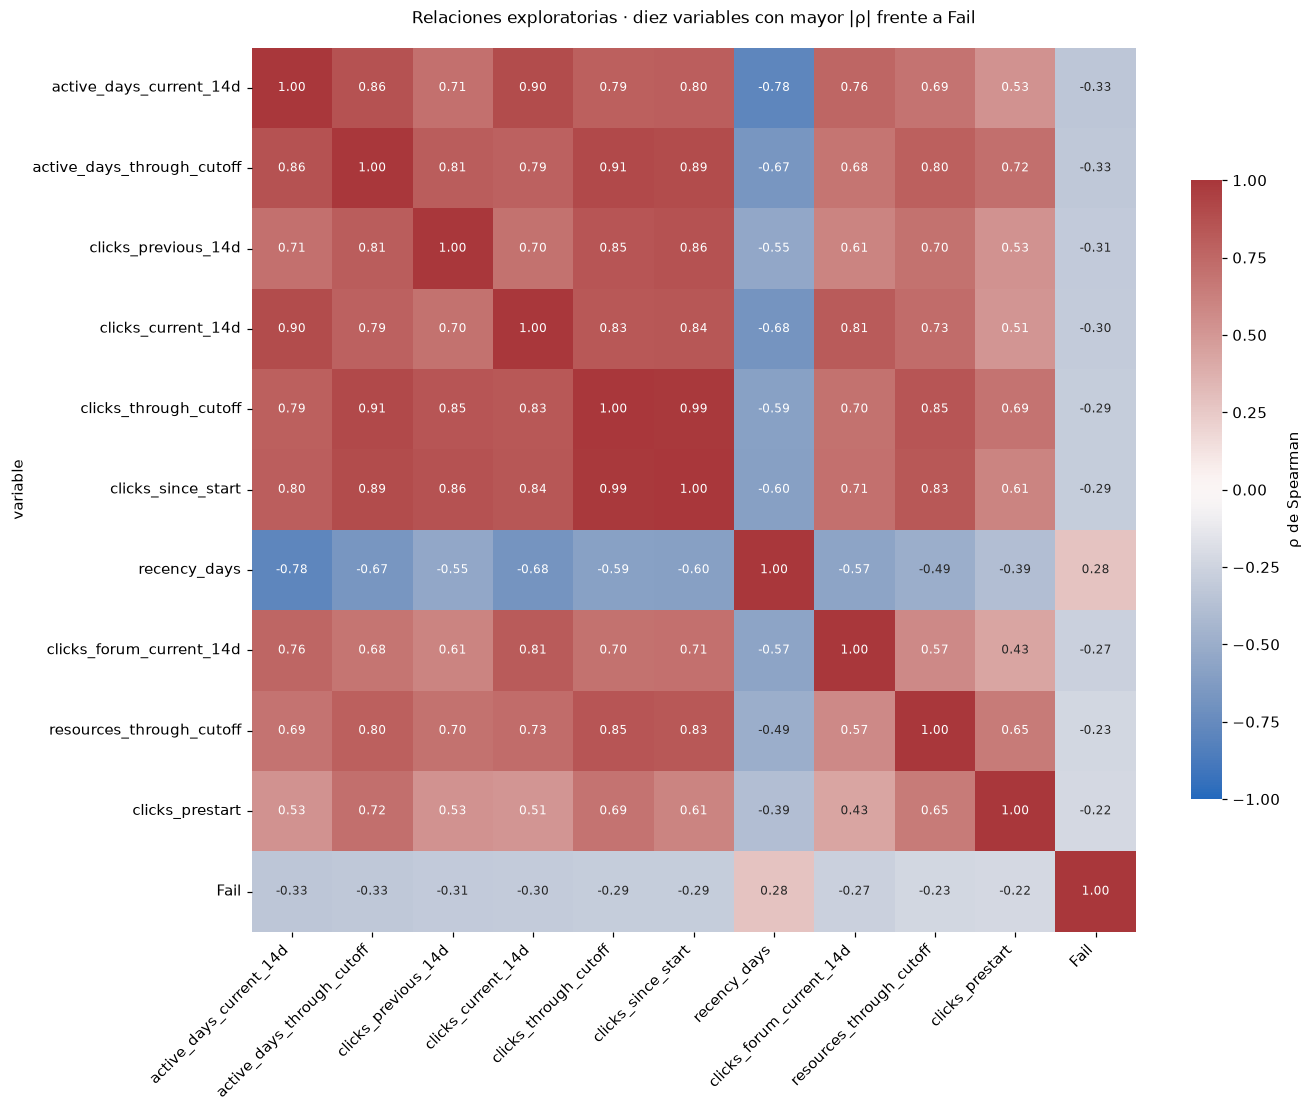

target_class,Approved,Fail,Withdrawn
variable,,,
num_of_prev_attempts,0.0000,0.0000,0.0000
studied_credits,60.0000,60.0000,60.0000
module_presentation_length,241.0000,241.0000,241.0000
registration_days_before_start,53.0000,52.0000,53.0000
clicks_through_cutoff,463.0000,188.0000,295.5000
clicks_since_start,395.0000,159.0000,257.0000
clicks_prestart,39.0000,11.0000,22.0000
clicks_day_zero,0.0000,0.0000,0.0000
active_days_through_cutoff,27.0000,13.0000,18.0000


,variable_a,variable_b,rho_spearman
0,clicks_through_cutoff,clicks_since_start,0.9887
1,clicks_through_cutoff,active_days_through_cutoff,0.9125


In [7]:
display(t['correlacion_fail'].round(4))
display(plots['05_correlaciones_spearman']); plt.close(plots['05_correlaciones_spearman'])
display(t['medianas_target'].round(3))
display(t['redundancia'].round(4))

Correlaciones altas entre acumulados y ventanas sugieren redundancia, pero no bastan para borrar variables. Se comparará el aporte con CV congelada y ablaciones. La mediana del cambio puede coincidir entre clases aunque sus distribuciones difieran; una única medida central no describe todo el patrón.

## 6. Registros de actividad y contexto

Las tasas siguientes describen desarrollo y no son métricas de un clasificador. No tener registros no equivale a no estudiar. Se distingue ausencia hasta el corte de ausencia únicamente en la ventana reciente. Los códigos de módulo y presentación se usan para contextualizar heterogeneidad y evaluar posteriormente; no se incorporan automáticamente como predictores.

,has_recorded_activity,n,n_fail,tasa_fail
0,False,432,327,0.7569
1,True,15899,4591,0.2888


,estado_actividad,n,n_fail,tasa_fail
0,"Registros previos, no recientes",2170,1291,0.5949
1,Registros recientes,13729,3300,0.2404
2,Sin registros hasta 56,432,327,0.7569


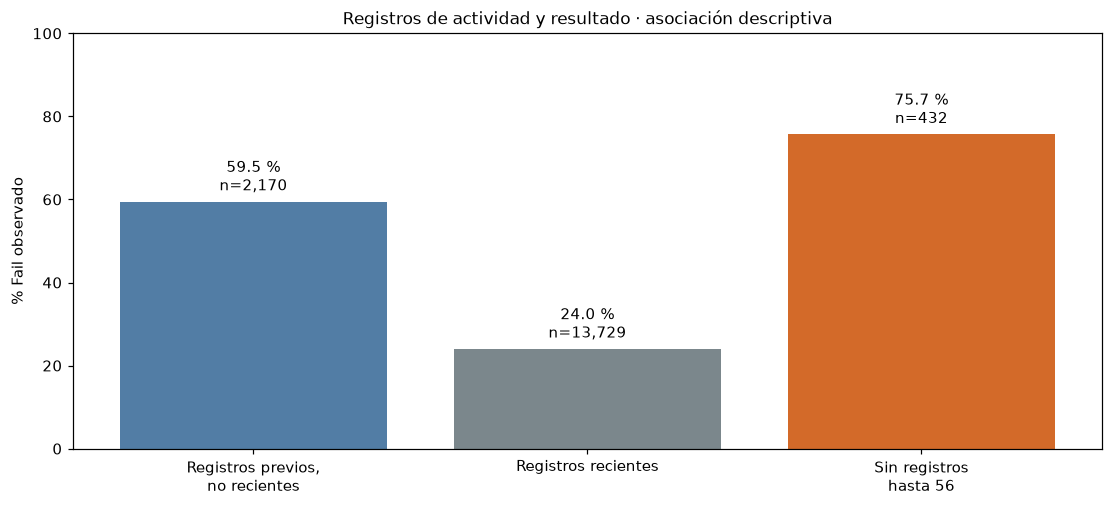

,code_module,n,n_fail,tasa_fail
0,AAA,335,42,0.1254
1,BBB,4411,1344,0.3047
2,CCC,1240,372,0.3000
3,DDD,3192,996,0.3120
4,EEE,1240,342,0.2758
5,FFF,4255,1276,0.2999
6,GGG,1658,546,0.3293


,code_presentation,n,n_fail,tasa_fail
0,2013B,3862,1203,0.3115
1,2013J,6801,1923,0.2828
2,2014B,5668,1792,0.3162


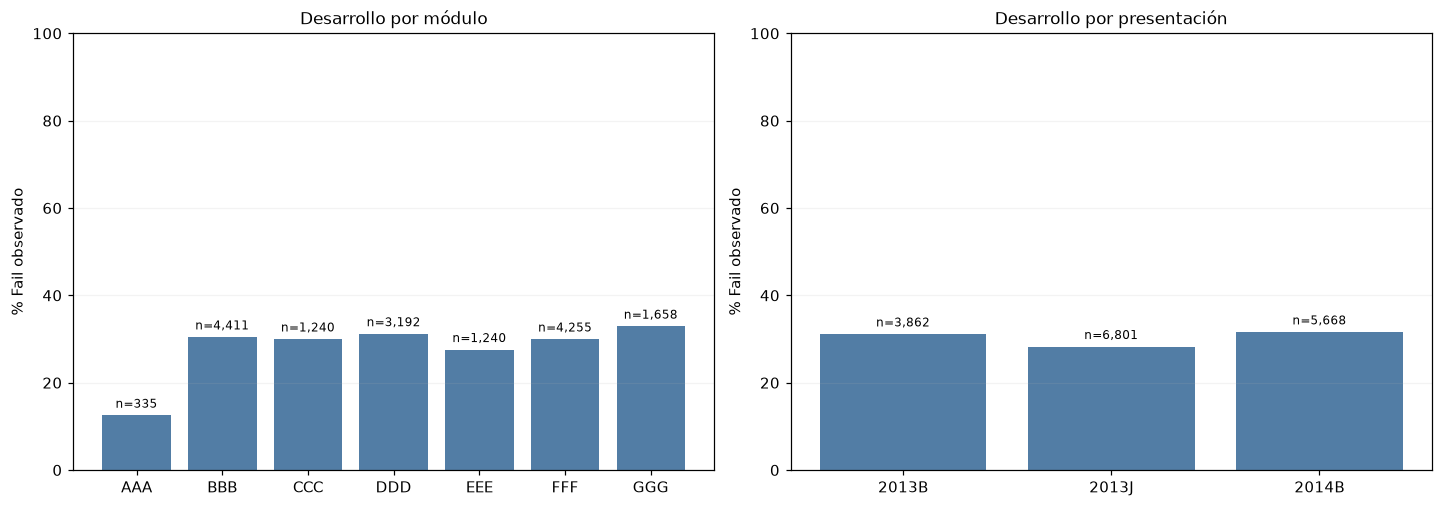

In [8]:
display(t['actividad_registrada'].round(4))
display(t['estado_actividad'].round(4))
display(plots['07_estado_actividad']); plt.close(plots['07_estado_actividad'])
display(t['tasas_modulo'].round(4)); display(t['tasas_presentacion'].round(4))
display(plots['06_contexto_modulo_presentacion']); plt.close(plots['06_contexto_modulo_presentacion'])

## 7. Hallazgos y decisiones para la etapa de features

La tabla enlaza evidencia con acciones. Los prototipos `log1p_clicks_current_14d` y `clicks_per_active_day_14d` usan solo registros disponibles hasta el corte; la intensidad deja NULL si no hay días activos en la ventana. Se muestran sus medianas observadas, **sin afirmar que aporten capacidad predictiva**. La próxima etapa implementará las transformaciones y probará su aporte dentro de CV; no se modificó todavía `src/pipeline.py`.

In [9]:
findings = hallazgos(result)
rows = ['| Hallazgo | Evidencia | Consecuencia en el experimento |', '|---|---|---|']
for finding in findings:
    rows.append('| ' + ' | '.join(str(finding[k]).replace('|', '\|') for k in ['hallazgo','evidencia','consecuencia']) + ' |')
display(Markdown(chr(10).join(rows)))
display(t['candidatas_derivadas'].round(4))

| Hallazgo | Evidencia | Consecuencia en el experimento |
|---|---|---|
| Desbalance multiclase relevante para Fail | Approved=9,219, Fail=4,918, Withdrawn=2,194; Fail=30.11 %; razón mayor/menor=4.20. | Mantener AP para Fail y cobertura a cupo fijo; informar calibración y métricas por clase. Accuracy de mayoría es solo referencia descriptiva, no criterio de selección ni baseline ya entrenado. Comparar pesos de clase únicamente dentro de CV. |
| Clics con cola larga; outliers no implican errores | clicks_current_14d: mediana=53, p99=686.1, máximo=7028, asimetría=8.82; IQR marca 1,158 y \|Z\|≥3 marca 264 observaciones. | Conservar filas. Probar log1p de clics actuales en la etapa de features y comparar por ablación con los mismos folds. No aplicar log1p al cambio quincenal, que puede ser negativo. Cualquier recorte aprendido debe ajustarse solo dentro del fold. |
| Ausencia de registros con recencia desconocida | 432 matrículas (2.65 %) sin registros; Fail=75.69 %, frente a 28.88 % con registros. Recencia falta exactamente en esos casos. | Preservar las matrículas y distinguir desconocido de cero. Mantener indicadores y justificar imputación dentro del Pipeline; no asignar recencia cero a ausencia de registros ni inferir actividad académica real. Evaluar estado/indicador de registros como candidato, sin interpretar causalidad. |
| Faltantes de razón quincenal son estructurales | click_ratio_14d falta en 2,516 matrículas (15.41 %), exactamente cuando clicks_previous_14d=0. IMD falta en 577 (3.53 %). | No convertir razón indefinida en cero ni borrar esas filas. Conservar indicador de denominador cero si se usa la razón. Prototipar clics por día activo con denominador positivo y NULL en ausencia de días activos; codificar IMD con política explícita dentro del fold. |
| Actividad reciente se asocia a Fail, sin demostrar rendimiento | Spearman(Fail,active_days_current_14d)=-0.332; Spearman(Fail,clicks_current_14d)=-0.304. Las medianas por clase y las tasas por módulo/presentación se muestran separadas. | Conservar comparación estático/longitudinal y evaluar intensidad normalizada por días activos como candidata. No seleccionar un ganador ni eliminar variables solo por correlación marginal. Los códigos de módulo/presentación siguen siendo contexto, no predictores automáticos. |
| IQR degenerado en antecedentes discretos | num_of_prev_attempts tiene IQR=0; la regla marca 2,147 casos, aunque los valores positivos representan intentos previos registrados. | Informar la bandera estadística sin tratarla como error de calidad ni borrar reintentos. Z-score tampoco es un test de anomalía con normalidad demostrada. Mantener estos antecedentes hasta comparar su aporte dentro de CV. |

,variable_candidata,clase,n_observado,n_faltante,mediana
0,log1p_clicks_current_14d,Approved,9219,0,4.3567
1,log1p_clicks_current_14d,Fail,4918,0,2.9957
2,log1p_clicks_current_14d,Withdrawn,2194,0,3.6109
3,clicks_per_active_day_14d,Approved,8716,503,15.1250
4,clicks_per_active_day_14d,Fail,3300,1618,13.3542
5,clicks_per_active_day_14d,Withdrawn,1713,481,13.5000


## 8. Exportación y trazabilidad en MLflow

Se guardan tablas y figuras agregadas en `docs/eda/`, junto con IDs de snapshot/split y hashes. No se publican filas individuales. Se registra una corrida de fase `eda`, adicional al presupuesto mínimo de modelos: no contiene un modelo entrenado y no se contabiliza como baseline/candidato/tuning/final. Cada Restart/Run All genera una corrida EDA distinta con la misma identidad de datos y fuentes; la fecha y el run_id distinguen ejecuciones.

In [10]:
reference=json.loads((BASE/'docs/portabilidad/referencias-historicas.json').read_text())['eda']
assert reference['snapshot_id']==s['snapshot_id'] and reference['split_id']==s['split_id']
assert reference['rows']==s['rows'] and reference['unique_students']==s['unique_students']
output=exportar(result,plots)
s.update({k:reference[k] for k in ['run_id','experiment_id','notebook_source_sha256','git_commit','git_dirty'] if k in reference})
s['replay_entrega']='EDA recalculado; run_id identifica el experimento histórico, no una corrida nueva'
(output/'resumen.json').write_text(json.dumps(s,ensure_ascii=False,indent=2,allow_nan=False)+chr(10))
history=pd.read_csv(BASE/'docs/corridas.csv')
assert history.loc[history.run_id.eq(reference['run_id']),'status'].eq('FINISHED').all()
print('EDA recalculado y verificado contra la evidencia histórica:',reference['run_id'])
print('Sin corridas nuevas; sin análisis nuevo de hold-out.')


EDA recalculado y verificado contra la evidencia histórica: 84ae066af3ca446d83828d6772e18079
Sin corridas nuevas; sin análisis nuevo de hold-out.


## Cierre y límites

EDA completada exclusivamente en desarrollo. Las asociaciones se usan para proponer experimentos y no son resultados de generalización. Las etiquetas de OULAD no incluyen timestamps de publicación; los registros no prueban cobertura completa de actividad real. La comparación prospectiva institucional y el efecto de tutorías siguen fuera de esta evidencia.

**Siguiente paso:** dos features derivadas, disponibilidad al inferir y ablación con folds congelados; política de faltantes/codificación dentro de `Pipeline` y `ColumnTransformer`. El hold-out seguirá reservado hasta fijar los dos finalistas.